# 01 - Data Understanding

## Project: Movie Recommendation System

### Objective

The objective of this notebook is to understand the structure, 
features, relationships, and quality of the TMDB 5000 Movie 
and Credits datasets before beginning data preprocessing.

### Datasets

1. TMDB 5000 Movies Dataset
2. TMDB 5000 Credits Dataset

### Key Activities

- Load and inspect datasets.
- Understand dataset dimensions and structure.
- Explore column names and data types.
- Identify missing values and duplicate records.
- Understand the relationship between datasets.
- Document initial observations.

### Expected Outcome

Develop a clear understanding of the available movie data 
and identify potential issues that need to be addressed 
during the preprocessing stage.

## 1. Import Libraries

Import the necessary Python libraries for data loading, 
inspection, analysis, and visualization.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Remove the column limit so all DataFrame columns are printed
pd.set_option("display.max_columns", None)

# Increase the row limit from the default (60) to 100 rows
pd.set_option("display.max_rows", 100)


sns.set_theme(style="whitegrid")

print("Libraries imported successfully.")

Libraries imported successfully.


In [24]:
import warnings
warnings.filterwarnings('ignore')


## 2. Define Dataset Paths

Define the project directory and paths to the raw TMDB datasets.

Using pathlib makes file paths easier to manage across operating systems.

In [25]:
PROJECT_ROOT = Path.cwd().parent

DATA_DIR = PROJECT_ROOT / "data" / "raw"

MOVIES_PATH = DATA_DIR / "tmdb_5000_movies.csv"
CREDITS_PATH = DATA_DIR / "tmdb_5000_credits.csv"

print("Project Root:", PROJECT_ROOT)
print("Movies Dataset:", MOVIES_PATH)
print("Credits Dataset:", CREDITS_PATH)

# Gives Assertion Error
assert MOVIES_PATH.exists(), "Movies dataset not found!"
assert CREDITS_PATH.exists(), "Credits dataset not found!"

Project Root: d:\Learning-Materials\Projects\ML-Projects\Content-Based-Movie-Recommendation-System
Movies Dataset: d:\Learning-Materials\Projects\ML-Projects\Content-Based-Movie-Recommendation-System\data\raw\tmdb_5000_movies.csv
Credits Dataset: d:\Learning-Materials\Projects\ML-Projects\Content-Based-Movie-Recommendation-System\data\raw\tmdb_5000_credits.csv


## 3. Load Datasets

Load the movie metadata and credits datasets into separate 
Pandas DataFrames.

In [26]:
movies_df = pd.read_csv(MOVIES_PATH)
credits_df = pd.read_csv(CREDITS_PATH)

print("Both datasets loaded successfully.")

Both datasets loaded successfully.


In [27]:
display(movies_df.head())
display(credits_df.head())

,budget,genres,homepage,id,keywords,original_language,original_title,overview,popularity,production_companies,production_countries,release_date,revenue,runtime,spoken_languages,status,tagline,title,vote_average,vote_count
0,237000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",http://www.avatarmovie.com/,19995,"[{""id"": 1463, ""name"": ""culture clash""}, {""id"":...",en,Avatar,"In the 22nd century, a paraplegic Marine is di...",150.437577,"[{""name"": ""Ingenious Film Partners"", ""id"": 289...","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",2009-12-10,2787965087,162.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}, {""iso...",Released,Enter the World of Pandora.,Avatar,7.2,11800
1,300000000,"[{""id"": 12, ""name"": ""Adventure""}, {""id"": 14, ""...",http://disney.go.com/disneypictures/pirates/,285,"[{""id"": 270, ""name"": ""ocean""}, {""id"": 726, ""na...",en,Pirates of the Caribbean: At World's End,"Captain Barbossa, long believed to be dead, ha...",139.082615,"[{""name"": ""Walt Disney Pictures"", ""id"": 2}, {""...","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",2007-05-19,961000000,169.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,"At the end of the world, the adventure begins.",Pirates of the Caribbean: At World's End,6.9,4500
2,245000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",http://www.sonypictures.com/movies/spectre/,206647,"[{""id"": 470, ""name"": ""spy""}, {""id"": 818, ""name...",en,Spectre,A cryptic message from Bond’s past sends him o...,107.376788,"[{""name"": ""Columbia Pictures"", ""id"": 5}, {""nam...","[{""iso_3166_1"": ""GB"", ""name"": ""United Kingdom""...",2015-10-26,880674609,148.0,"[{""iso_639_1"": ""fr"", ""name"": ""Fran\u00e7ais""},...",Released,A Plan No One Escapes,Spectre,6.3,4466
3,250000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 80, ""nam...",http://www.thedarkknightrises.com/,49026,"[{""id"": 849, ""name"": ""dc comics""}, {""id"": 853,...",en,The Dark Knight Rises,Following the death of District Attorney Harve...,112.312950,"[{""name"": ""Legendary Pictures"", ""id"": 923}, {""...","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",2012-07-16,1084939099,165.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,The Legend Ends,The Dark Knight Rises,7.6,9106
4,260000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",http://movies.disney.com/john-carter,49529,"[{""id"": 818, ""name"": ""based on novel""}, {""id"":...",en,John Carter,"John Carter is a war-weary, former military ca...",43.926995,"[{""name"": ""Walt Disney Pictures"", ""id"": 2}]","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",2012-03-07,284139100,132.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,"Lost in our world, found in another.",John Carter,6.1,2124


,movie_id,title,cast,crew
0,19995,Avatar,"[{""cast_id"": 242, ""character"": ""Jake Sully"", ""...","[{""credit_id"": ""52fe48009251416c750aca23"", ""de..."
1,285,Pirates of the Caribbean: At World's End,"[{""cast_id"": 4, ""character"": ""Captain Jack Spa...","[{""credit_id"": ""52fe4232c3a36847f800b579"", ""de..."
2,206647,Spectre,"[{""cast_id"": 1, ""character"": ""James Bond"", ""cr...","[{""credit_id"": ""54805967c3a36829b5002c41"", ""de..."
3,49026,The Dark Knight Rises,"[{""cast_id"": 2, ""character"": ""Bruce Wayne / Ba...","[{""credit_id"": ""52fe4781c3a36847f81398c3"", ""de..."
4,49529,John Carter,"[{""cast_id"": 5, ""character"": ""John Carter"", ""c...","[{""credit_id"": ""52fe479ac3a36847f813eaa3"", ""de..."


## 4. Dataset Overview

Examine the overall dimensions of both datasets to understand 
the number of records and features available.

In [28]:
print("MOVIES DATASET")
print("Rows:", movies_df.shape[0])
print("Columns:", movies_df.shape[1])

print("\nCREDITS DATASET")
print("Rows:", credits_df.shape[0])
print("Columns:", credits_df.shape[1])

MOVIES DATASET
Rows: 4803
Columns: 20

CREDITS DATASET
Rows: 4803
Columns: 4


In [29]:
dataset_summary = pd.DataFrame({
    "Dataset": ["Movies", "Credits"],
    "Rows": [movies_df.shape[0], credits_df.shape[0]],
    "Columns": [movies_df.shape[1], credits_df.shape[1]]
})

display(dataset_summary)

,Dataset,Rows,Columns
0,Movies,4803,20
1,Credits,4803,4


## 5. Inspect Dataset Structure

Examine the structure of each DataFrame, including column 
names, non-null values, and data types.

In [30]:
print("MOVIES DATASET INFORMATION")
movies_df.info()

print("\nCREDITS DATASET INFORMATION")
credits_df.info()

MOVIES DATASET INFORMATION
<class 'pandas.DataFrame'>
RangeIndex: 4803 entries, 0 to 4802
Data columns (total 20 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   budget                4803 non-null   int64  
 1   genres                4803 non-null   str    
 2   homepage              1712 non-null   str    
 3   id                    4803 non-null   int64  
 4   keywords              4803 non-null   str    
 5   original_language     4803 non-null   str    
 6   original_title        4803 non-null   str    
 7   overview              4800 non-null   str    
 8   popularity            4803 non-null   float64
 9   production_companies  4803 non-null   str    
 10  production_countries  4803 non-null   str    
 11  release_date          4802 non-null   str    
 12  revenue               4803 non-null   int64  
 13  runtime               4801 non-null   float64
 14  spoken_languages      4803 non-null   str    
 15  statu

In [31]:
print("Movies Columns:")
print(movies_df.columns.tolist())

print("\nCredits Columns:")
print(credits_df.columns.tolist())

Movies Columns:
['budget', 'genres', 'homepage', 'id', 'keywords', 'original_language', 'original_title', 'overview', 'popularity', 'production_companies', 'production_countries', 'release_date', 'revenue', 'runtime', 'spoken_languages', 'status', 'tagline', 'title', 'vote_average', 'vote_count']

Credits Columns:
['movie_id', 'title', 'cast', 'crew']


## 6. Understanding Dataset Columns

Identify the meaning and potential usefulness of important 
columns for building a content-based recommendation system.

In [32]:
column_overview = pd.DataFrame({
    "Column": movies_df.columns,
    "Data Type": movies_df.dtypes.astype(str).values,
    "Non-Null Count": movies_df.notna().sum().values,
    "Missing Count": movies_df.isna().sum().values,
    "Unique Values": movies_df.nunique().values
})

display(column_overview)

,Column,Data Type,Non-Null Count,Missing Count,Unique Values
0,budget,int64,4803,0,436
1,genres,str,4803,0,1175
2,homepage,str,1712,3091,1691
3,id,int64,4803,0,4803
4,keywords,str,4803,0,4222
5,original_language,str,4803,0,37
6,original_title,str,4803,0,4801
7,overview,str,4800,3,4800
8,popularity,float64,4803,0,4802
9,production_companies,str,4803,0,3697


In [33]:
credits_column_overview = pd.DataFrame({
    "Column": credits_df.columns,
    "Data Type": credits_df.dtypes.astype(str).values,
    "Non-Null Count": credits_df.notna().sum().values,
    "Missing Count": credits_df.isna().sum().values,
    "Unique Values": credits_df.nunique().values
})

display(credits_column_overview)

,Column,Data Type,Non-Null Count,Missing Count,Unique Values
0,movie_id,int64,4803,0,4803
1,title,str,4803,0,4800
2,cast,str,4803,0,4761
3,crew,str,4803,0,4776


## 7. Inspect Sample Records

Examine selected movie records and credits records to 
understand how information is represented.

Pay particular attention to nested JSON-like columns 
such as genres, keywords, cast, and crew.

In [34]:
display(
    movies_df[
        ["id", "title", "genres", "keywords", "overview"]
    ].head(5)
)

,id,title,genres,keywords,overview
0,19995,Avatar,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...","[{""id"": 1463, ""name"": ""culture clash""}, {""id"":...","In the 22nd century, a paraplegic Marine is di..."
1,285,Pirates of the Caribbean: At World's End,"[{""id"": 12, ""name"": ""Adventure""}, {""id"": 14, ""...","[{""id"": 270, ""name"": ""ocean""}, {""id"": 726, ""na...","Captain Barbossa, long believed to be dead, ha..."
2,206647,Spectre,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...","[{""id"": 470, ""name"": ""spy""}, {""id"": 818, ""name...",A cryptic message from Bond’s past sends him o...
3,49026,The Dark Knight Rises,"[{""id"": 28, ""name"": ""Action""}, {""id"": 80, ""nam...","[{""id"": 849, ""name"": ""dc comics""}, {""id"": 853,...",Following the death of District Attorney Harve...
4,49529,John Carter,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...","[{""id"": 818, ""name"": ""based on novel""}, {""id"":...","John Carter is a war-weary, former military ca..."


In [35]:
display(
    credits_df[
        ["movie_id", "title", "cast", "crew"]
    ].head(5)
)

,movie_id,title,cast,crew
0,19995,Avatar,"[{""cast_id"": 242, ""character"": ""Jake Sully"", ""...","[{""credit_id"": ""52fe48009251416c750aca23"", ""de..."
1,285,Pirates of the Caribbean: At World's End,"[{""cast_id"": 4, ""character"": ""Captain Jack Spa...","[{""credit_id"": ""52fe4232c3a36847f800b579"", ""de..."
2,206647,Spectre,"[{""cast_id"": 1, ""character"": ""James Bond"", ""cr...","[{""credit_id"": ""54805967c3a36829b5002c41"", ""de..."
3,49026,The Dark Knight Rises,"[{""cast_id"": 2, ""character"": ""Bruce Wayne / Ba...","[{""credit_id"": ""52fe4781c3a36847f81398c3"", ""de..."
4,49529,John Carter,"[{""cast_id"": 5, ""character"": ""John Carter"", ""c...","[{""credit_id"": ""52fe479ac3a36847f813eaa3"", ""de..."


In [36]:
print("Sample Genres:")
print(movies_df["genres"].iloc[0])

print("\nSample Cast:")
print(credits_df["cast"].iloc[0])

print("\nSample Crew:")
print(credits_df["crew"].iloc[0])

Sample Genres:
[{"id": 28, "name": "Action"}, {"id": 12, "name": "Adventure"}, {"id": 14, "name": "Fantasy"}, {"id": 878, "name": "Science Fiction"}]

Sample Cast:
[{"cast_id": 242, "character": "Jake Sully", "credit_id": "5602a8a7c3a3685532001c9a", "gender": 2, "id": 65731, "name": "Sam Worthington", "order": 0}, {"cast_id": 3, "character": "Neytiri", "credit_id": "52fe48009251416c750ac9cb", "gender": 1, "id": 8691, "name": "Zoe Saldana", "order": 1}, {"cast_id": 25, "character": "Dr. Grace Augustine", "credit_id": "52fe48009251416c750aca39", "gender": 1, "id": 10205, "name": "Sigourney Weaver", "order": 2}, {"cast_id": 4, "character": "Col. Quaritch", "credit_id": "52fe48009251416c750ac9cf", "gender": 2, "id": 32747, "name": "Stephen Lang", "order": 3}, {"cast_id": 5, "character": "Trudy Chacon", "credit_id": "52fe48009251416c750ac9d3", "gender": 1, "id": 17647, "name": "Michelle Rodriguez", "order": 4}, {"cast_id": 8, "character": "Selfridge", "credit_id": "52fe48009251416c750ac9e1"

## 8. Data Types and Memory Usage

Understand the data types and memory consumption of both 
datasets to identify potential optimization opportunities.

In [37]:
print("Movies Data Types:")
display(movies_df.dtypes.value_counts())

print("\nCredits Data Types:")
display(credits_df.dtypes.value_counts())

movies_memory = movies_df.memory_usage(deep=True).sum() / (1024 ** 2)
credits_memory = credits_df.memory_usage(deep=True).sum() / (1024 ** 2)

print(f"Movies Memory Usage: {movies_memory:.2f} MB")
print(f"Credits Memory Usage: {credits_memory:.2f} MB")

Movies Data Types:


str        13
int64       4
float64     3
Name: count, dtype: int64


Credits Data Types:


str      3
int64    1
Name: count, dtype: int64

Movies Memory Usage: 7.94 MB
Credits Memory Usage: 34.34 MB


## 9. Missing Values Analysis

Identify missing values in both datasets.

This analysis will help determine which columns require 
special attention during data preprocessing.

In [38]:
movies_missing = movies_df.isnull().sum()
credits_missing = credits_df.isnull().sum()

print("Movies Missing Values:")
display(movies_missing[ movies_missing > 0 ].sort_values(ascending=False))

print("Credits Missing Values:")
display(credits_missing[ credits_missing > 0 ].sort_values(ascending=False))

Movies Missing Values:


homepage        3091
tagline          844
overview           3
runtime            2
release_date       1
dtype: int64

Credits Missing Values:


Series([], dtype: int64)

IndexError: index 0 is out of bounds for axis 0 with size 0

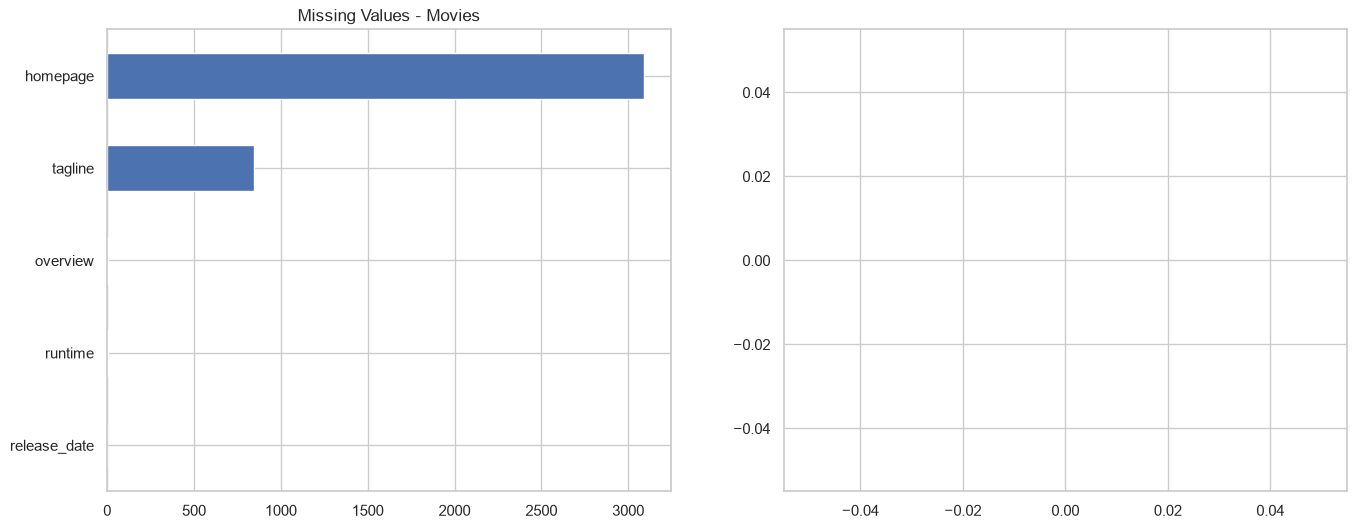

In [39]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

movies_missing[movies_missing > 0].sort_values().plot(
    kind="barh",
    ax=axes[0]
)
axes[0].set_title("Missing Values - Movies")

credits_missing[credits_missing > 0].sort_values().plot(
    kind="barh",
    ax=axes[1]
)
axes[1].set_title("Missing Values - Credits")

plt.tight_layout()
plt.show()

## 10. Duplicate Records Analysis

Check for duplicate rows and repeated movie identifiers.

Duplicate records can affect the accuracy of dataset merging 
and recommendation generation.

In [40]:
print("Movies Duplicate Rows:", movies_df.duplicated().sum())
print("Credits Duplicate Rows:", credits_df.duplicated().sum())

print(
    "Movies Duplicate IDs:",
    movies_df["id"].duplicated().sum()
)

print(
    "Credits Duplicate Movie IDs:",
    credits_df["movie_id"].duplicated().sum()
)

Movies Duplicate Rows: 0
Credits Duplicate Rows: 0
Movies Duplicate IDs: 0
Credits Duplicate Movie IDs: 0


## 11. Dataset Relationship Analysis

Investigate the relationship between the movies and credits 
datasets.

The movie identifier in the movies dataset and the movie_id 
column in the credits dataset are expected to identify 
corresponding movies.

This relationship will be used during data integration.

In [41]:
movies_ids = set(movies_df["id"])
credits_ids = set(credits_df["movie_id"])

common_ids = movies_ids.intersection(credits_ids)

print("Movies IDs:", len(movies_ids))
print("Credits IDs:", len(credits_ids))
print("Common IDs:", len(common_ids))
print("Movies Without Credits:", len(movies_ids - credits_ids))
print("Credits Without Movies:", len(credits_ids - movies_ids))

Movies IDs: 4803
Credits IDs: 4803
Common IDs: 4803
Movies Without Credits: 0
Credits Without Movies: 0


In [42]:
matched = movies_df[["id", "title"]].merge(
    credits_df[["movie_id", "title"]],
    left_on="id",
    right_on="movie_id",
    how="inner",
    suffixes=("_movies", "_credits")
)

title_mismatches = matched[
    matched["title_movies"] != matched["title_credits"]
]

print("Matched Records:", len(matched))
print("Title Mismatches:", len(title_mismatches))

display(title_mismatches.head())

Matched Records: 4803
Title Mismatches: 0


,id,title_movies,movie_id,title_credits


## 12. Initial Observations

### Dataset Structure
- The movies dataset contains movie metadata.
- The credits dataset contains cast and crew information.
- Both datasets can be connected through movie identifiers.

### Important Features
- Genres
- Keywords
- Overview
- Cast
- Crew

### Potential Data Quality Issues
- Missing values in selected columns.
- Possible duplicate records.
- Structured text stored as string values.
- Different data types across columns.

### Preprocessing Requirements
- Handle missing values.
- Investigate duplicate identifiers.
- Parse structured JSON-like columns.
- Extract relevant movie attributes.
- Merge the datasets using movie identifiers.

Note: Update these observations based on the actual analysis results.

## 13. Conclusion

The initial exploration provided an understanding of the 
TMDB 5000 Movies and Credits datasets.

The datasets contain useful information for developing 
a content-based movie recommendation system.

The next stage will focus on exploratory data analysis 
and understanding the distributions, patterns, and 
relationships within the movie data.

### Next Notebook

02 - Exploratory Data Analysis